<a href="https://colab.research.google.com/github/tncoe-cbe/Batch-3-ANP-D7361-/blob/main/AI/NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

# Input features
study_hours = 0.8
attendance = 0.6

# Weights
w1 = 0
w2 = 0


# Weighted sum
z = (study_hours * w1) + (attendance * w2)

# Sigmoid activation function
output = 1 / (1 + np.exp(-z))

print("Weighted sum:", z)
print("Neuron output:", output)

Weighted sum: 0.0
Neuron output: 0.5


In [ ]:
import numpy as np

# One sample with two input features
X = np.array([[0.8, 0.6]])

# Weights connecting the input layer to the hidden layer
W1 = np.array([
    [0.5, 0.3],
    [0.2, 0.7]
])

# Biases for the hidden layer
b1 = np.array([[0.1, -0.2]])

# Weights connecting the hidden layer to the output layer
W2 = np.array([
    [0.6],
    [0.4]
])

# Bias for the output layer
b2 = np.array([[0.1]])


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# Forward propagation: input -> hidden layer
z1 = np.dot(X, W1) + b1

# ReLU activation in hidden layer
A1 = np.maximum(0, z1)

# Hidden layer -> output layer
z2 = np.dot(A1, W2) + b2

# Sigmoid activation in output layer
A2 = sigmoid(z2)

print("Input:", X)
print("Hidden layer weighted sums:", z1)
print("Hidden layer activations:", A1)
print("Output layer weighted sum:", z2)
print("Final output:", A2)

Input: [[0.8 0.6]]
Hidden layer weighted sums: [[0.62 0.46]]
Hidden layer activations: [[0.62 0.46]]
Output layer weighted sum: [[0.656]]
Final output: [[0.65836127]]


In [ ]:
%pip install tensorflow

In [ ]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Reproducibility for this demonstration
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# Features: [normalised study hours, normalised attendance]
X = np.array([
    [0.1, 0.2],
    [0.2, 0.3],
    [0.3, 0.4],
    [0.4, 0.5],
    [0.5, 0.4],
    [0.6, 0.6],
    [0.7, 0.6],
    [0.8, 0.7],
    [0.9, 0.8],
    [0.7, 0.9],
    [0.2, 0.8],
    [0.9, 0.3]
], dtype=np.float32)

# Binary labels: 0 = fail, 1 = pass
y = np.array([
    [0], [0], [0], [0],
    [0], [1], [1], [1],
    [1], [1], [0], [1]
], dtype=np.float32)

In [ ]:
model = Sequential([
    Dense(4, activation="relu", input_shape=(2,)),
    Dense(1, activation="sigmoid")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (68.00 B)

 Trainable params: 17 (68.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=4,
    verbose=0
)

In [ ]:
new_student = np.array([[0.3, 0.7]], dtype=np.float32)

prediction = model.predict(new_student, verbose=0)

print("Predicted score:", float(prediction[0][0]))

if prediction[0][0] >= 0.5:
    print("Predicted class: Pass")
else:
    print("Predicted class: Fail")

Predicted score: 0.002548811724409461
Predicted class: Fail


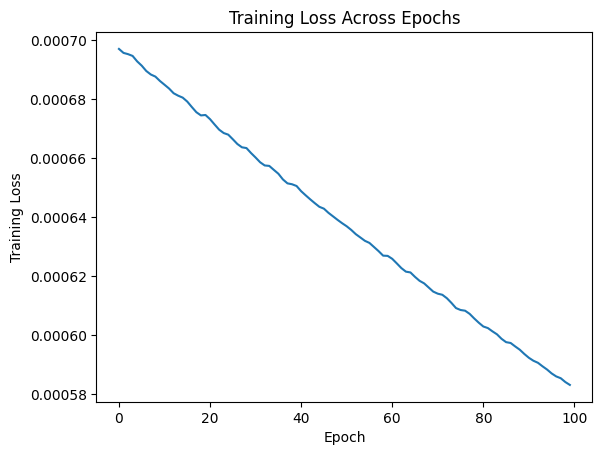

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Across Epochs")
plt.show()

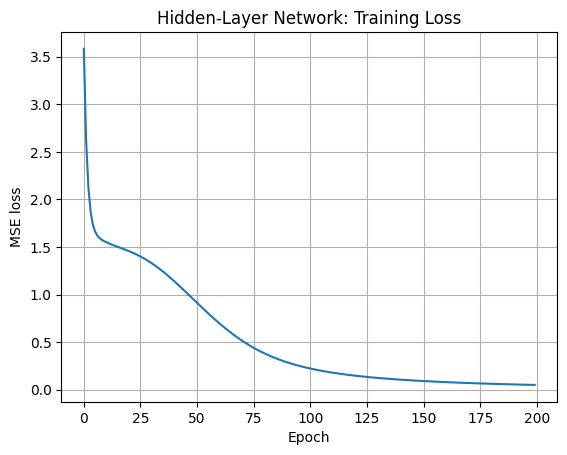

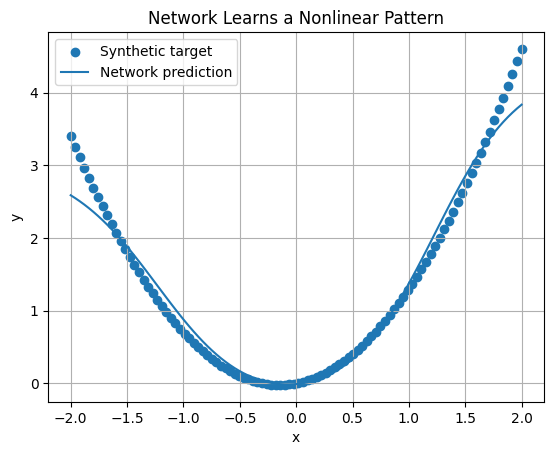

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 8)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27 (112.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(7)
X_nn = np.linspace(-2, 2, 100).reshape(-1, 1).astype("float32")
y_nn = (X_nn**2 + 0.3*X_nn).astype("float32")

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(8, activation="tanh"),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01), loss="mse")
history_nn = model.fit(X_nn, y_nn, epochs=200, batch_size=16, verbose=0)

plt.figure()
plt.plot(history_nn.history["loss"])
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title("Hidden-Layer Network: Training Loss"); plt.grid(True); plt.show()

pred_nn = model.predict(X_nn, verbose=0)
plt.figure()
plt.scatter(X_nn.ravel(), y_nn.ravel(), label="Synthetic target")
plt.plot(X_nn.ravel(), pred_nn.ravel(), label="Network prediction")
plt.xlabel("x"); plt.ylabel("y")
plt.title("Network Learns a Nonlinear Pattern")
plt.legend(); plt.grid(True); plt.show()
model.summary()

Epoch  20 | Loss: 2.213368 | Mean |W1|: 0.3259
Epoch  40 | Loss: 1.770933 | Mean |W1|: 0.3234
Epoch  60 | Loss: 1.608985 | Mean |W1|: 0.3183
Epoch  80 | Loss: 1.531337 | Mean |W1|: 0.3128
Epoch 100 | Loss: 1.478103 | Mean |W1|: 0.3083
Epoch 120 | Loss: 1.432548 | Mean |W1|: 0.3051
Epoch 140 | Loss: 1.389888 | Mean |W1|: 0.3034
Epoch 160 | Loss: 1.348468 | Mean |W1|: 0.3033
Epoch 180 | Loss: 1.307520 | Mean |W1|: 0.3047
Epoch 200 | Loss: 1.266586 | Mean |W1|: 0.3075

Final MSE: 1.264533967870478
W1 shape: (1, 8)
b1 shape: (1, 8)
W2 shape: (8, 1)
b2 shape: (1, 1)


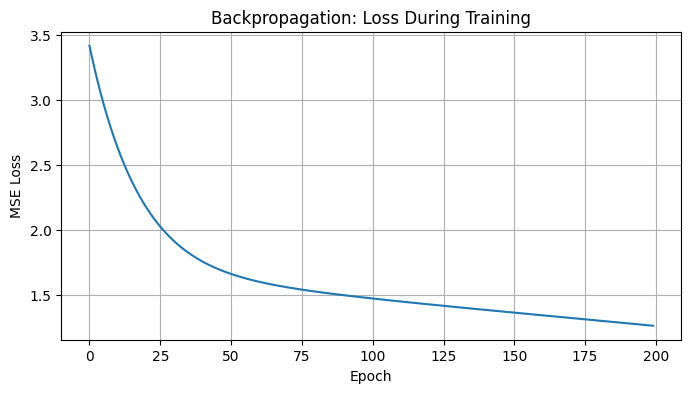

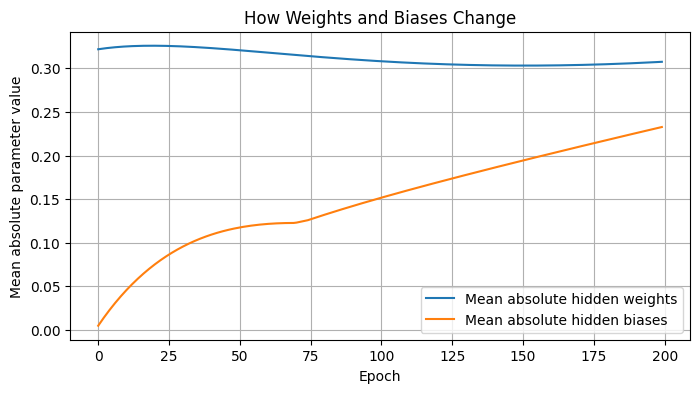

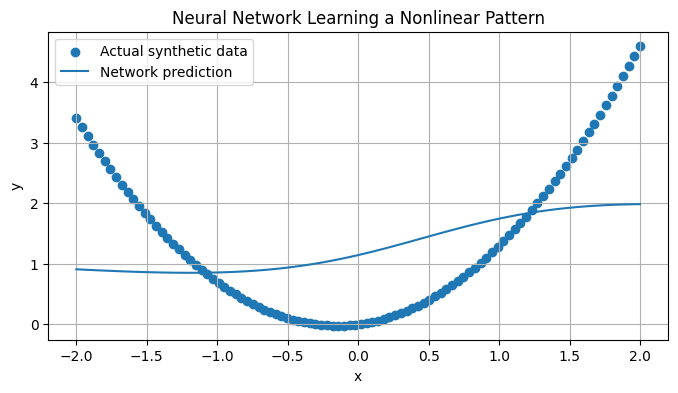

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(7)

# 1. Dataset: same as the TensorFlow example
X = np.linspace(-2, 2, 100).reshape(-1, 1).astype(np.float32)
y = (X**2 + 0.3 * X).astype(np.float32)

# 2. Network architecture
input_size = 1
hidden_size = 8
output_size = 1

# Initialise weights and biases
W1 = np.random.randn(input_size, hidden_size) * 0.5
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.5
b2 = np.zeros((1, output_size))

# Training configuration
learning_rate = 0.01
epochs = 200
n = len(X)

loss_history = []
weight_history = []
bias_history = []

# 3. Training loop
for epoch in range(epochs):

    # ===================================
    # FORWARD PROPAGATION
    # ===================================

    # Input -> Hidden layer
    Z1 = X @ W1 + b1
    A1 = np.tanh(Z1)

    # Hidden layer -> Output layer
    Z2 = A1 @ W2 + b2

    # Linear output activation
    y_pred = Z2

    # ===================================
    # LOSS CALCULATION
    # ===================================

    loss = np.mean((y_pred - y) ** 2)
    loss_history.append(loss)

    # ===================================
    # BACKPROPAGATION
    # ===================================

    # Gradient of MSE with respect to predictions
    dZ2 = (2 / n) * (y_pred - y)

    # Output layer gradients
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Propagate gradient backward to hidden layer
    dA1 = dZ2 @ W2.T

    # Derivative of tanh:
    # d(tanh(z))/dz = 1 - tanh(z)^2
    dZ1 = dA1 * (1 - A1**2)

    # Hidden layer gradients
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # ===================================
    # UPDATE WEIGHTS AND BIASES
    # ===================================

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    # Record parameter values for visualisation
    weight_history.append(np.mean(np.abs(W1)))
    bias_history.append(np.mean(np.abs(b1)))

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {loss:.6f} | "
            f"Mean |W1|: {weight_history[-1]:.4f}"
        )

# ===================================
# FINAL PREDICTIONS
# ===================================

Z1 = X @ W1 + b1
A1 = np.tanh(Z1)
y_pred = A1 @ W2 + b2

final_loss = np.mean((y_pred - y) ** 2)

print("\nFinal MSE:", final_loss)
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

# ===================================
# VISUALISATION 1: LOSS
# ===================================

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Backpropagation: Loss During Training")
plt.grid(True)
plt.show()

# ===================================
# VISUALISATION 2: WEIGHTS AND BIASES
# ===================================

plt.figure(figsize=(8, 4))
plt.plot(weight_history, label="Mean absolute hidden weights")
plt.plot(bias_history, label="Mean absolute hidden biases")
plt.xlabel("Epoch")
plt.ylabel("Mean absolute parameter value")
plt.title("How Weights and Biases Change")
plt.legend()
plt.grid(True)
plt.show()

# ===================================
# VISUALISATION 3: PREDICTIONS
# ===================================

plt.figure(figsize=(8, 4))
plt.scatter(X.ravel(), y.ravel(), label="Actual synthetic data")
plt.plot(X.ravel(), y_pred.ravel(), label="Network prediction")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Neural Network Learning a Nonlinear Pattern")
plt.legend()
plt.grid(True)
plt.show()


Initial loss: 4.080908298492432


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer (Dense)            │ (None, 8)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch  20 | Loss: 1.493517
Epoch  40 | Loss: 1.232285
Epoch  60 | Loss: 0.600138
Epoch  80 | Loss: 0.097852
Epoch 100 | Loss: 0.028309
Epoch 120 | Loss: 0.013317
Epoch 140 | Loss: 0.009131
Epoch 160 | Loss: 0.008863
Epoch 180 | Loss: 0.007555
Epoch 200 | Loss: 0.006676

Initial loss: 4.080908298492432
Final loss: 0.006675852928310633


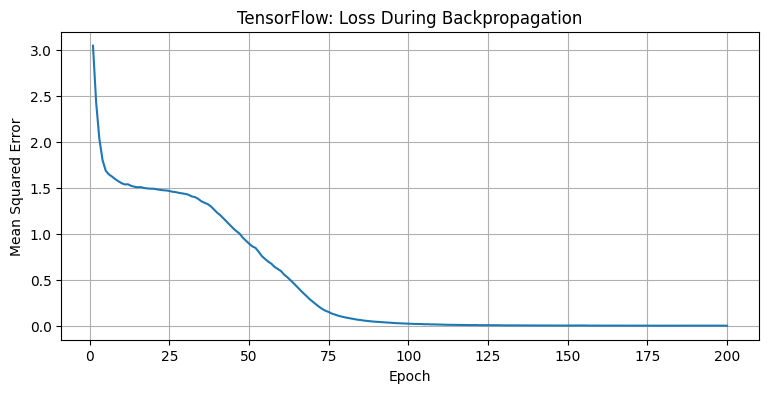

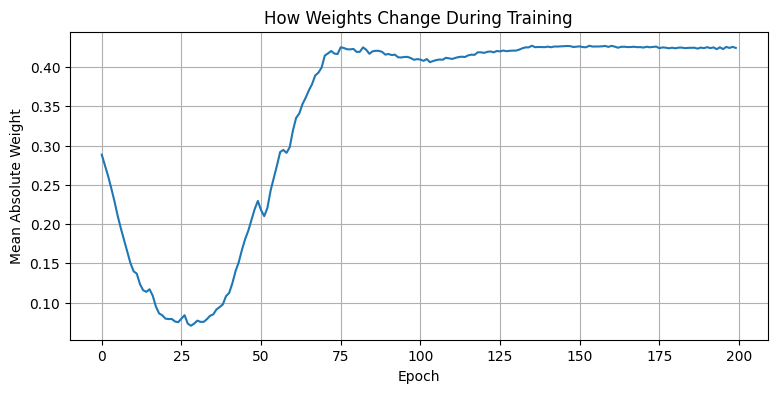

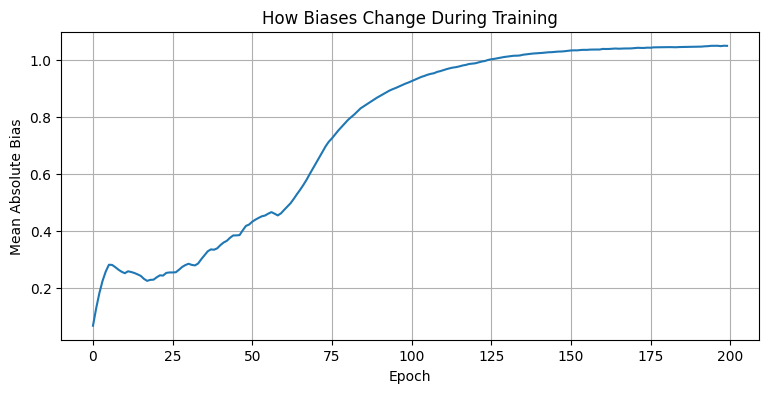

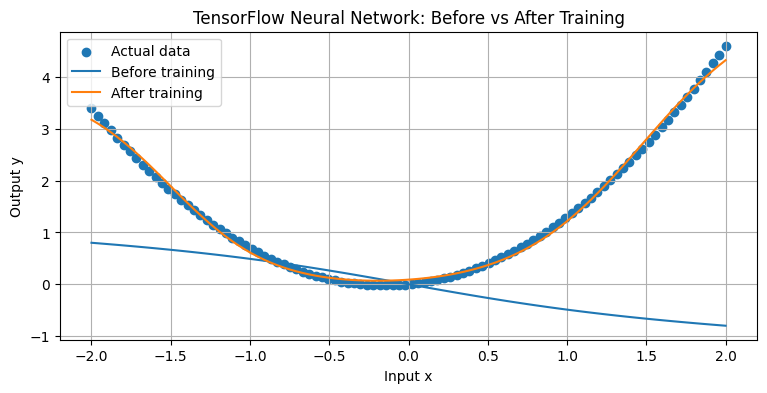


Layer: hidden_layer
Weight matrix shape: (1, 8)
Weights:
 [[ 0.0411624   1.2606021   0.35532686 -1.5580212   0.04072693 -0.04129323
  -0.05172068 -0.04539767]]
Bias shape: (8,)
Biases:
 [ 0.80047065 -1.8563484   0.1950198  -2.342896    0.80876124 -0.870722
 -0.62688076 -0.8918242 ]

Layer: output_layer
Weight matrix shape: (8, 1)
Weights:
 [[ 1.3685974 ]
 [ 2.745777  ]
 [-0.40235832]
 [ 1.9911023 ]
 [ 1.4418235 ]
 [-1.3029772 ]
 [-0.76432455]
 [-1.046932  ]]
Bias shape: (1,)
Biases:
 [0.7769727]


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. CREATE SYNTHETIC DATASET
# ==========================================

tf.keras.utils.set_random_seed(7)

X = np.linspace(-2, 2, 100).reshape(-1, 1).astype("float32")
y = (X**2 + 0.3 * X).astype("float32")

# ==========================================
# 2. BUILD THE NEURAL NETWORK
# ==========================================

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(8, activation="tanh", name="hidden_layer"),
    tf.keras.layers.Dense(1, name="output_layer")
])

# Adam optimiser and MSE loss
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
loss_function = tf.keras.losses.MeanSquaredError()

# ==========================================
# 3. RECORD INITIAL PARAMETERS
# ==========================================

initial_weights = [
    variable.numpy().copy()
    for variable in model.trainable_variables
]

# Initial predictions
initial_predictions = model(X, training=False).numpy()

initial_loss = float(
    loss_function(y, initial_predictions).numpy()
)

print("Initial loss:", initial_loss)
model.summary()

# ==========================================
# 4. TRAIN USING TENSORFLOW AUTODIFFERENTIATION
# ==========================================

epochs = 200
batch_size = 16

dataset = tf.data.Dataset.from_tensor_slices((X, y))
dataset = dataset.shuffle(
    buffer_size=len(X),
    seed=7,
    reshuffle_each_iteration=True
).batch(batch_size)

loss_history = []
weight_history = []
bias_history = []

for epoch in range(epochs):

    batch_losses = []

    for X_batch, y_batch in dataset:

        # FORWARD PROPAGATION + LOSS
        with tf.GradientTape() as tape:

            predictions = model(X_batch, training=True)

            loss = loss_function(y_batch, predictions)

        # BACKPROPAGATION
        gradients = tape.gradient(
            loss,
            model.trainable_variables
        )

        # UPDATE WEIGHTS AND BIASES USING ADAM
        optimizer.apply_gradients(
            zip(gradients, model.trainable_variables)
        )

        batch_losses.append(float(loss.numpy()))

    # Evaluate the entire dataset after the epoch
    epoch_predictions = model(X, training=False)
    epoch_loss = float(
        loss_function(y, epoch_predictions).numpy()
    )

    loss_history.append(epoch_loss)

    # Record average absolute parameter magnitudes
    weights = model.get_weights()

    weight_history.append(
        np.mean(np.abs(weights[0]))
    )

    bias_history.append(
        np.mean(np.abs(weights[1]))
    )

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {epoch_loss:.6f}"
        )

# ==========================================
# 5. FINAL PREDICTIONS
# ==========================================

final_predictions = model(X, training=False).numpy()

final_loss = float(
    loss_function(y, final_predictions).numpy()
)

print("\nInitial loss:", initial_loss)
print("Final loss:", final_loss)

# ==========================================
# 6. CHART 1: LOSS DURING TRAINING
# ==========================================

plt.figure(figsize=(9, 4))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("TensorFlow: Loss During Backpropagation")
plt.grid(True)
plt.show()

# ==========================================
# 7. CHART 2: WEIGHT CHANGES
# ==========================================

plt.figure(figsize=(9, 4))
plt.plot(weight_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Weight")
plt.title("How Weights Change During Training")
plt.grid(True)
plt.show()

# ==========================================
# 8. CHART 3: BIAS CHANGES
# ==========================================

plt.figure(figsize=(9, 4))
plt.plot(bias_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Bias")
plt.title("How Biases Change During Training")
plt.grid(True)
plt.show()

# ==========================================
# 9. CHART 4: PREDICTIONS BEFORE AND AFTER
# ==========================================

plt.figure(figsize=(9, 4))

plt.scatter(
    X.ravel(),
    y.ravel(),
    label="Actual data"
)

plt.plot(
    X.ravel(),
    initial_predictions.ravel(),
    label="Before training"
)

plt.plot(
    X.ravel(),
    final_predictions.ravel(),
    label="After training"
)

plt.xlabel("Input x")
plt.ylabel("Output y")
plt.title("TensorFlow Neural Network: Before vs After Training")
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# 10. INSPECT TRAINED WEIGHTS AND BIASES
# ==========================================

for layer in model.layers:

    weights = layer.get_weights()

    print(f"\nLayer: {layer.name}")

    if weights:
        print("Weight matrix shape:", weights[0].shape)
        print("Weights:\n", weights[0])

        print("Bias shape:", weights[1].shape)
        print("Biases:\n", weights[1])
